### Analytical TFIM thermal kernels: IPR vs HS
Using the thermal-appendix closed forms for $h=0$ and $h \rightarrow \infty$ to compare $K_{\text{IPR}}(\beta,n)$ and $K_{\text{HS}}(\beta,n)$.

Kernel definitions used in this notebook:

$K_{\mathrm{IPR}}(\beta,n)=\frac{1}{2^n}\,\frac{I_z(\beta,n)+I_x(\beta,n)}{\sqrt{4^{-n}+I_z(\beta,n)^2}\,\sqrt{4^{-n}+I_x(\beta,n)^2}}$

$K_{\mathrm{HS}}(\beta,n)=\frac{1}{2^n}\,\frac{Z^Z_{\beta,n}Z^X_{\beta,n}}{\sqrt{Z^Z_{2\beta,n}}\,\sqrt{Z^X_{2\beta,n}}}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def Z_x(beta, n):
    beta = np.asarray(beta, dtype=float)
    return (1.0 + np.exp(-2.0 * beta)) ** n


def Z_z(beta, n):
    beta = np.asarray(beta, dtype=float)
    e = np.exp(-2.0 * beta)
    return (1.0 + e) ** n + (1.0 - e) ** n


def I_z(beta, n):
    return Z_z(2.0 * beta, n) / (Z_z(beta, n) ** 2)


def I_x(beta, n):
    return Z_x(2.0 * beta, n) / (Z_x(beta, n) ** 2)


def K_ipr(beta, n):
    iz = I_z(beta, n)
    ix = I_x(beta, n)
    k_raw = (2.0 ** (-n)) * (iz + ix)
    four_pow_minus_n = 4.0 ** (-n)
    denom = np.sqrt(four_pow_minus_n + iz ** 2) * np.sqrt(four_pow_minus_n + ix ** 2)
    return k_raw / denom


def K_hs(beta, n):
    beta = np.asarray(beta, dtype=float)
    k_raw = np.full_like(beta, 2.0 ** (-n), dtype=float)
    purity_z = Z_z(2.0 * beta, n) / (Z_z(beta, n) ** 2)
    purity_x = Z_x(2.0 * beta, n) / (Z_x(beta, n) ** 2)
    return k_raw / np.sqrt(purity_z * purity_x)


def K_ipr_approx(beta, n):
    x = (beta ** 2) * n
    return 1.0 / np.cosh(x)


def K_hs_approx(beta, n):
    return np.exp(-(beta ** 2) * n)


def K_ipr_bound(beta, n):
    return np.exp(-0.5 * (beta ** 4) * (n ** 2))


IPR_COLOR = "#1b9e77"
HS_COLOR = "#d95f02"


def plot_analytic_kernels(
    n=20,
    beta_min=0.0,
    beta_max=3.0,
    n_beta=500,
    show_approximations=True,
    show_ipr_bound=False,
    show_title=True,
):
    beta = np.linspace(beta_min, beta_max, n_beta)
    k_ipr = K_ipr(beta, n)
    k_hs = K_hs(beta, n)

    plt.figure(figsize=(8, 5))

    plt.plot(beta, k_ipr, lw=2, color=IPR_COLOR, label=r"$K_{\mathrm{IPR}}$ (norm)")
    plt.plot(beta, k_hs, lw=2, color=HS_COLOR, label=r"$K_{\mathrm{HS}}$ (norm)")

    if show_approximations:
        plt.plot(beta, K_ipr_approx(beta, n), "--", lw=1.6, color=IPR_COLOR, label=r"$K_{\mathrm{IPR}}$ approx")
        plt.plot(beta, K_hs_approx(beta, n), "--", lw=1.6, color=HS_COLOR, label=r"$K_{\mathrm{HS}}$ approx")

    if show_ipr_bound:
        plt.plot(beta, K_ipr_bound(beta, n), ":", lw=1.8, label="IPR bound")

    plt.xlabel(r"$\beta$")
    plt.ylabel("Kernel value")
    plt.ylim(-0.02, 1.05)

    if show_title:
        plt.title(rf"Analytical kernels for TFIM thermal states ($n={n}$)")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

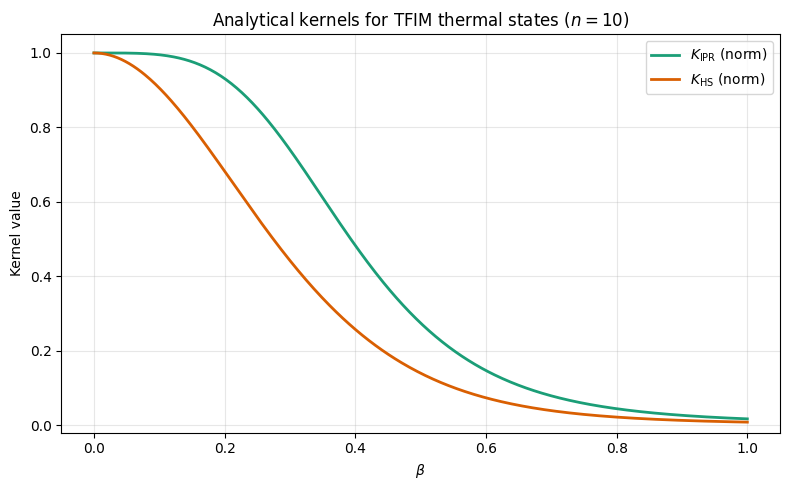

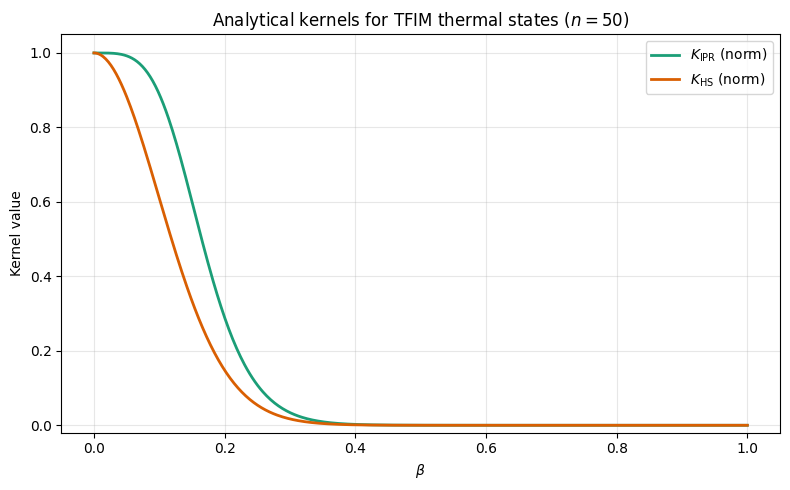

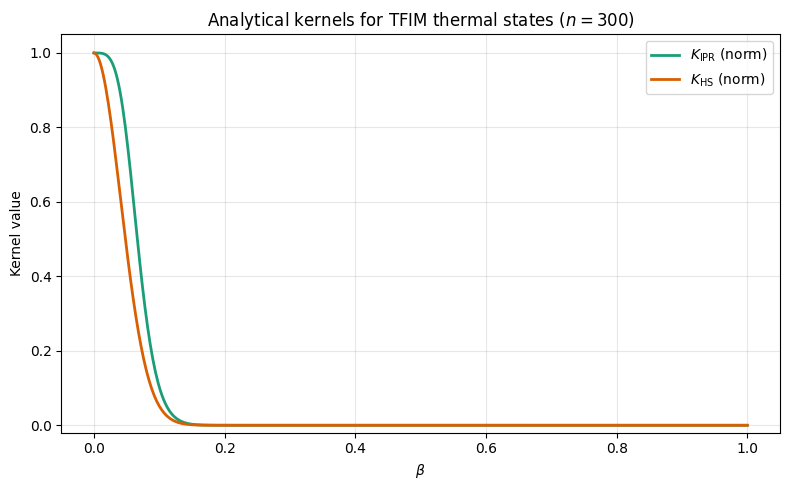

In [2]:
for n_val in [10, 50, 300]:
    plot_analytic_kernels(
        n=n_val,
        beta_min=0.0,
        beta_max=1.0,
        n_beta=500,
        show_approximations=False,
        show_ipr_bound=False,
        show_title=False,
    )